In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df = pd.read_csv(r"archive\netflix1.csv")

In [3]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
df.tail()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV
8789,s8786,TV Show,YOM,Not Given,Pakistan,6/7/2018,2016,TV-Y7,1 Season,Kids' TV


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [6]:
df.describe()

,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [7]:
df.shape

(8790, 10)

In [8]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='object')

### **Data Cleaning**

In [9]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [10]:
(df == 'Not Given').sum()

show_id            0
type               0
title              0
director        2588
country          287
date_added         0
release_year       0
rating             0
duration           0
listed_in          0
dtype: int64

In [11]:
(df == 'Not Given').mean() * 100

show_id          0.000000
type             0.000000
title            0.000000
director        29.442548
country          3.265074
date_added       0.000000
release_year     0.000000
rating           0.000000
duration         0.000000
listed_in        0.000000
dtype: float64

In [12]:
df.replace('Not Given' , 'Unknown' , inplace= True)

In [13]:
(df[['director' , 'country']] == 'Unknown').sum()

director    2588
country      287
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.duplicated(subset= df.columns.drop('show_id')).sum()

np.int64(3)

In [16]:
df[df.duplicated(subset= df.columns.drop('show_id') , keep= False)].sort_values('title')

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
2925,s3963,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
4261,s5967,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
3285,s4523,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4260,s5966,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
393,s3997,TV Show,9-Feb,Unknown,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
537,s5965,TV Show,9-Feb,Unknown,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"


In [17]:
df.drop_duplicates(subset= df.columns.drop('show_id') , inplace= True)
df.duplicated(subset= df.columns.drop('show_id')).sum()

np.int64(0)

In [18]:
df.reset_index(drop= True , inplace= True)
df.shape

(8787, 10)

In [19]:
df[df['title'] != df['title'].str.strip()]['title'].tolist()

['Consequences\xa0']

In [20]:
for col in ['title' , 'director' , 'country' , 'rating' , 'listed_in']:
    df[col] = df[col].str.strip()

In [21]:
(df['title'] != df['title'].str.strip()).sum()

np.int64(0)

### **Data Transformation**

In [22]:
df['date_added'] = pd.to_datetime(df['date_added'] , format= '%m/%d/%Y')

In [23]:
df['year_added'] = df['date_added'].dt.year

In [24]:
df['month_added'] = df['date_added'].dt.month

In [25]:
df['years_to_add'] = df['year_added'] - df['release_year']

In [26]:
df['duration_num'] = df['duration'].str.split().str[0].astype(int)

In [27]:
movies = df[df['type'] == 'Movie'].copy()
tv_shows = df[df['type'] == 'TV Show'].copy()

In [28]:
age_map = {'TV-Y': 'Kids' , 'TV-Y7': 'Kids' , 'TV-Y7-FV': 'Kids' , 'TV-G': 'Kids' , 'G': 'Kids' ,
           'TV-PG': 'Teens' , 'PG': 'Teens' , 'TV-14': 'Teens' , 'PG-13': 'Teens' ,
           'TV-MA': 'Adults' , 'R': 'Adults' , 'NC-17': 'Adults' ,
           'NR': 'Unrated' , 'UR': 'Unrated'}
df['age_group'] = df['rating'].map(age_map)

In [29]:
df['age_group'].isnull().sum()

np.int64(0)

In [30]:
genres = df['listed_in'].str.split(', ').explode()
genres.value_counts().head(10)

listed_in
International Movies        2752
Dramas                      2424
Comedies                    1673
International TV Shows      1348
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

In [31]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,years_to_add,duration_num,age_group
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,1,90,Teens
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,0,1,Adults
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,0,1,Adults
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,0,91,Teens
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,28,125,Adults


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8787 entries, 0 to 8786
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8787 non-null   object        
 1   type          8787 non-null   object        
 2   title         8787 non-null   object        
 3   director      8787 non-null   object        
 4   country       8787 non-null   object        
 5   date_added    8787 non-null   datetime64[ns]
 6   release_year  8787 non-null   int64         
 7   rating        8787 non-null   object        
 8   duration      8787 non-null   object        
 9   listed_in     8787 non-null   object        
 10  year_added    8787 non-null   int32         
 11  month_added   8787 non-null   int32         
 12  years_to_add  8787 non-null   int64         
 13  duration_num  8787 non-null   int64         
 14  age_group     8787 non-null   object        
dtypes: datetime64[ns](1), int32(2), int64(

### **EDA && Visualization**

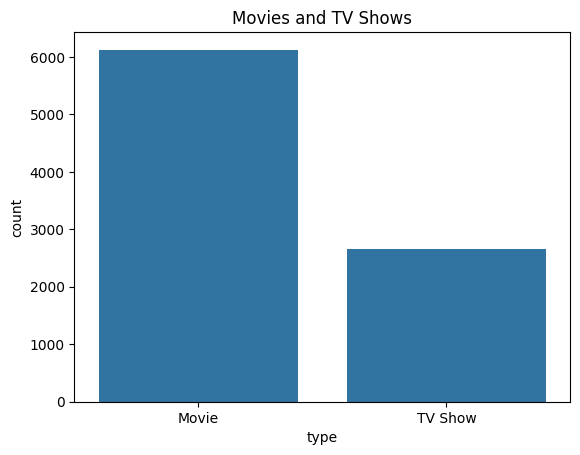

In [33]:
sns.countplot( x = 'type' , data= df)
plt.title('Movies and TV Shows')
plt.show()

In [34]:
df['type'].value_counts()

type
Movie      6124
TV Show    2663
Name: count, dtype: int64

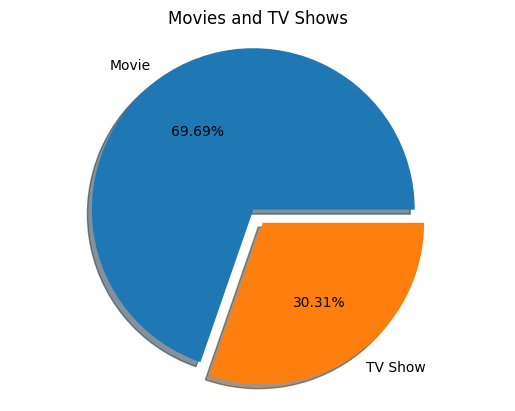

In [35]:
plt.pie(df['type'].value_counts() , 
        labels = df['type'].value_counts().index , 
        autopct = '%1.2f%%' , 
        shadow = True , 
        explode = [0 , 0.1])
plt.title('Movies and TV Shows')
plt.axis('equal')
plt.show()

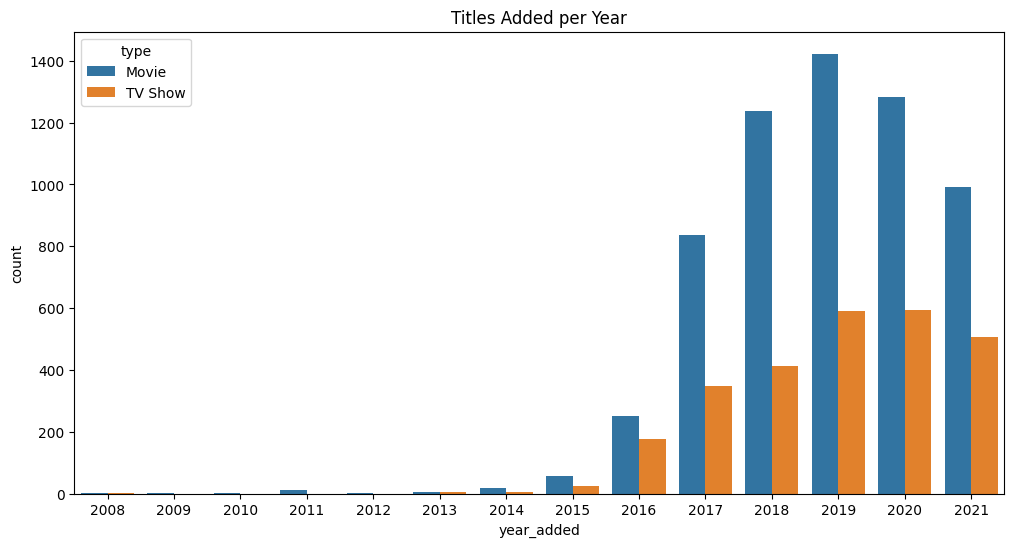

In [36]:
plt.figure(figsize= (12,6))
plt.title('Titles Added per Year')
sns.countplot(data= df , x= 'year_added' , hue= 'type')
plt.show()

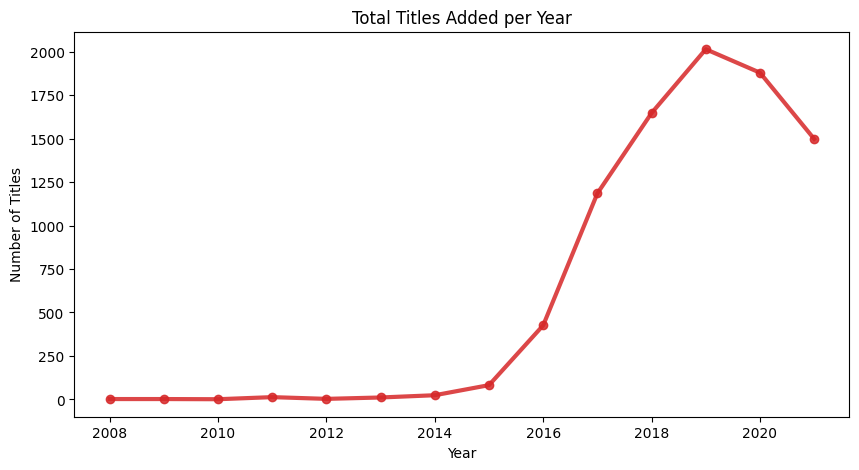

In [37]:
plt.figure(figsize=(10, 5))
plt.plot(
    df.groupby('year_added').size() ,
    ls='-',  
    marker='o',  
    lw=3,
    alpha=0.85,
    color='tab:red',
)

plt.title('Total Titles Added per Year')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.show()

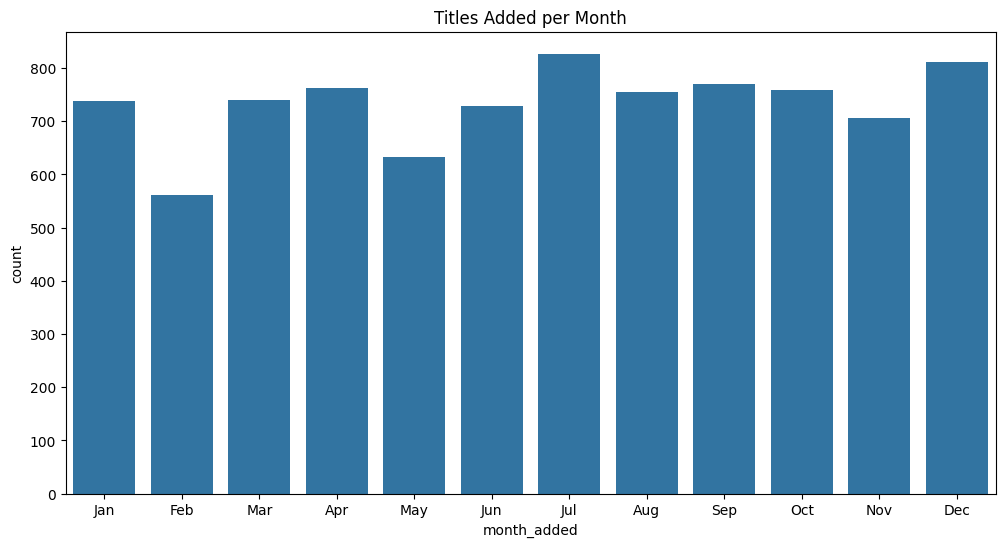

In [38]:
plt.figure(figsize=(12,6))
plt.title('Titles Added per Month')
sns.countplot(data=df , x='month_added')
plt.xticks(range(0,12),
           ['Jan' , 'Feb' , 'Mar' , 'Apr' , 'May' ,
             'Jun' , 'Jul' , 'Aug' , 'Sep' , 'Oct' , 'Nov' , 'Dec'])
plt.show()

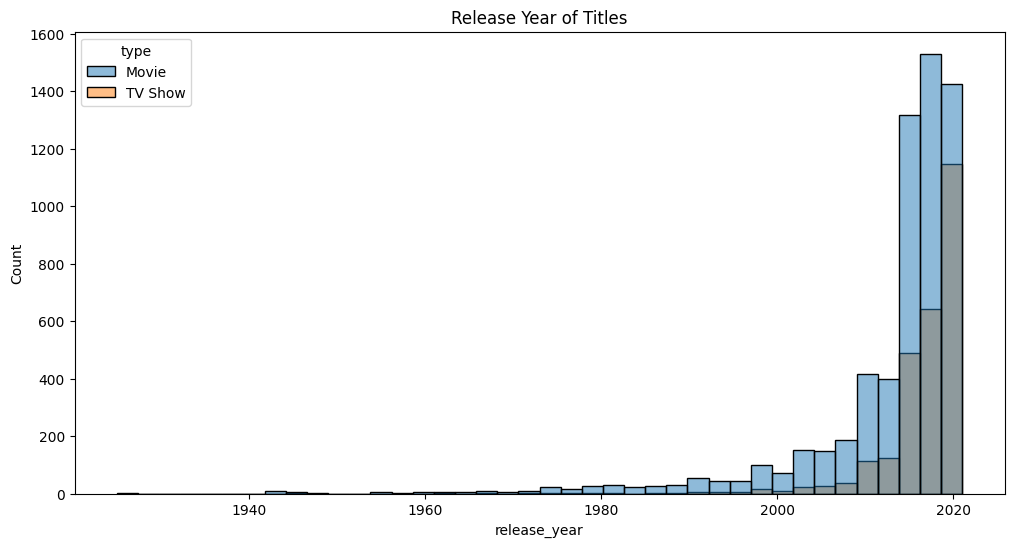

In [39]:
plt.figure(figsize=(12, 6))
plt.title('Release Year of Titles')
sns.histplot(data=df , x='release_year' , bins= 40 , hue= 'type')
plt.show()

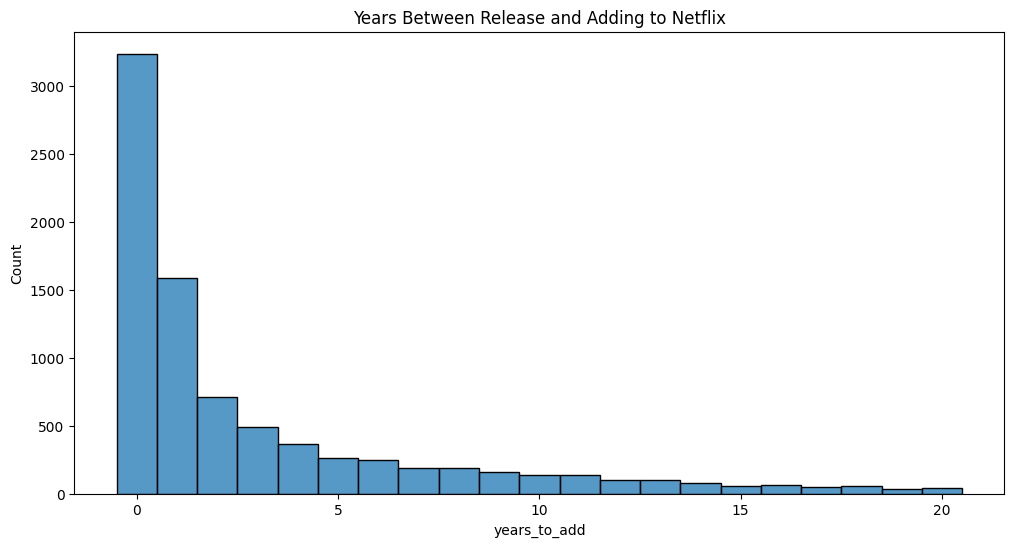

In [40]:
plt.figure(figsize=(12, 6))
plt.title('Years Between Release and Adding to Netflix')
sns.histplot(data= df[df['years_to_add'].between(0 , 20)] , x= 'years_to_add' , discrete= True)
plt.show()

In [41]:
df['years_to_add'].describe()

count    8787.000000
mean        4.691931
std         8.791157
min        -3.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: years_to_add, dtype: float64

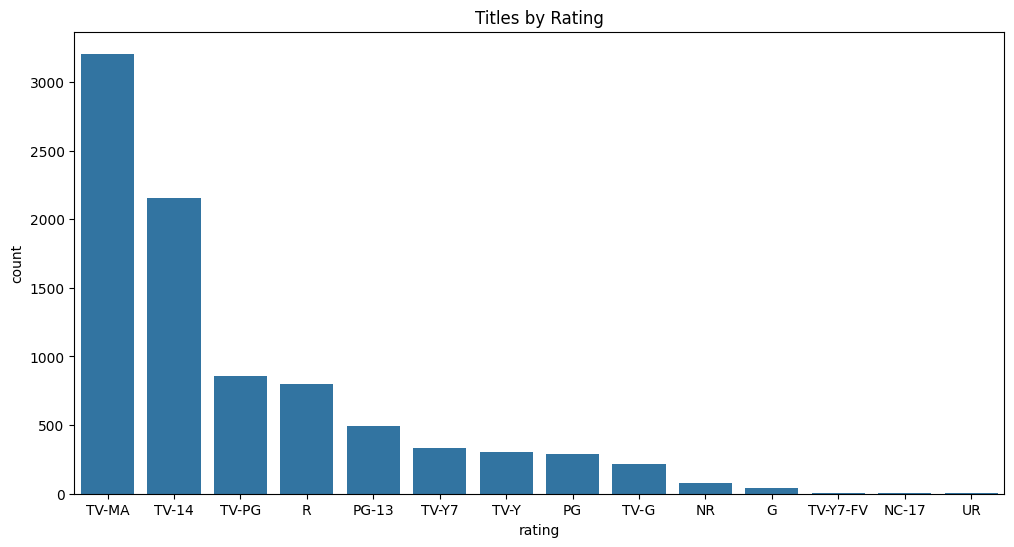

In [42]:
plt.figure(figsize= (12,6))
plt.title('Titles by Rating')
sns.countplot(data= df , x= 'rating' , order= df.rating.value_counts().index)
plt.show()

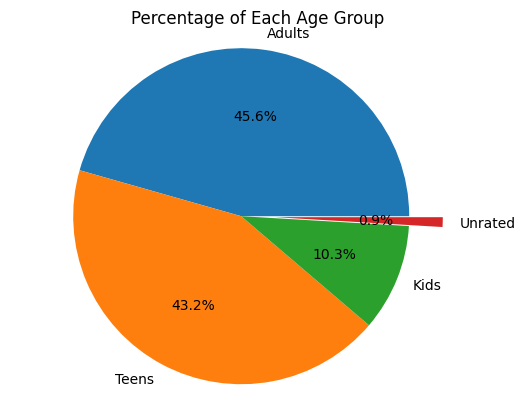

In [43]:
plt.pie(df['age_group'].value_counts() , 
        labels = df['age_group'].value_counts().index , 
        autopct = '%1.1f%%' , 
        explode = [0 , 0 , 0 , 0.2])
plt.title('Percentage of Each Age Group')
plt.axis('equal')
plt.show()

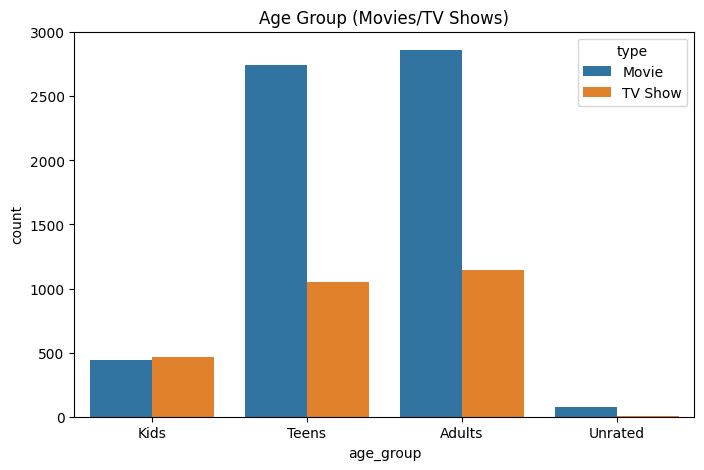

In [44]:
plt.figure(figsize= (8,5))
plt.title('Age Group (Movies/TV Shows)')
sns.countplot(data= df , x= 'age_group' , order= ['Kids' , 'Teens' , 'Adults' , 'Unrated'] , hue= 'type')
plt.show()

In [45]:
top_countries = df[df['country'] != 'Unknown']['country'].value_counts().head(10)
top_countries

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

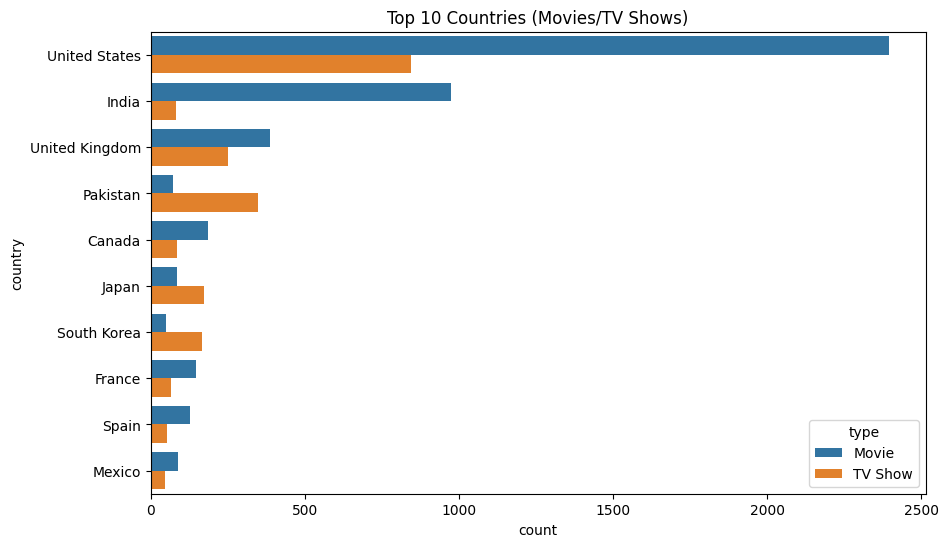

In [46]:
plt.figure(figsize= (10,6))
plt.title('Top 10 Countries (Movies/TV Shows)')
sns.countplot(data= df[df['country'].isin(top_countries.index)] , y= 'country' , order= top_countries.index , hue= 'type')
plt.show()

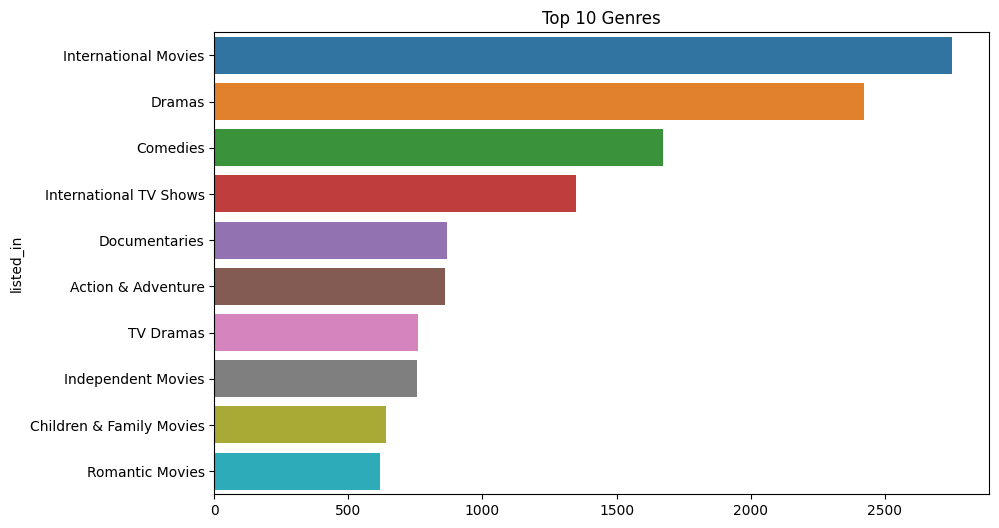

In [47]:
top_genres = genres.value_counts().head(10)

plt.figure(figsize= (10,6))
plt.title('Top 10 Genres')
sns.barplot( x = top_genres.values , y= top_genres.index , hue= top_genres.index)
plt.show()

In [48]:
directors = df[df['director'] != 'Unknown']['director'].str.split(', ').explode()
top_directors = directors.value_counts().head(10)
top_directors

director
Rajiv Chilaka          23
Jan Suter              21
Raúl Campos            19
Alastair Fothergill    19
Suhas Kadav            16
Marcus Raboy           16
Jay Karas              15
Cathy Garcia-Molina    13
Youssef Chahine        12
Jay Chapman            12
Name: count, dtype: int64

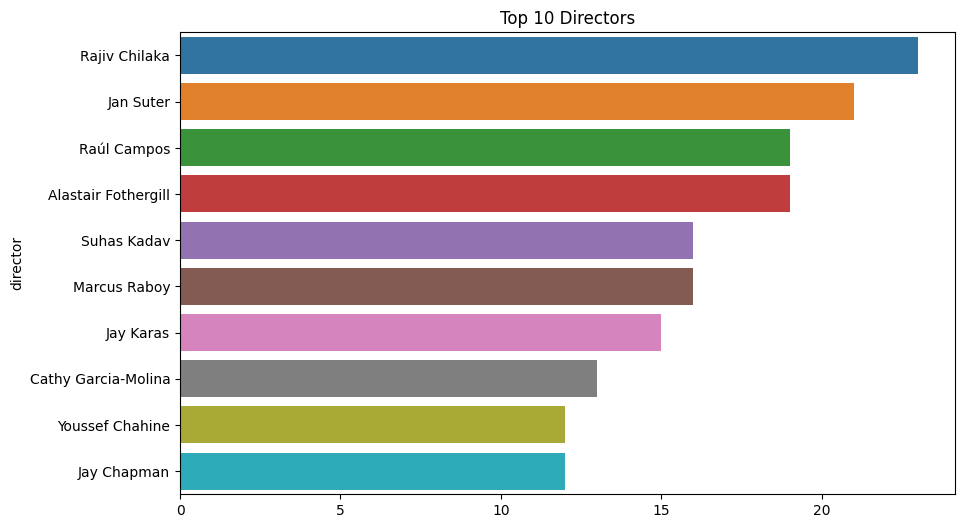

In [49]:
plt.figure(figsize= (10,6))
plt.title('Top 10 Directors')
sns.barplot( x = top_directors.values , y= top_directors.index , hue= top_directors.index)
plt.show()

In [50]:
movies['duration_num'].describe()

count    6124.000000
mean       99.573645
std        28.280425
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_num, dtype: float64

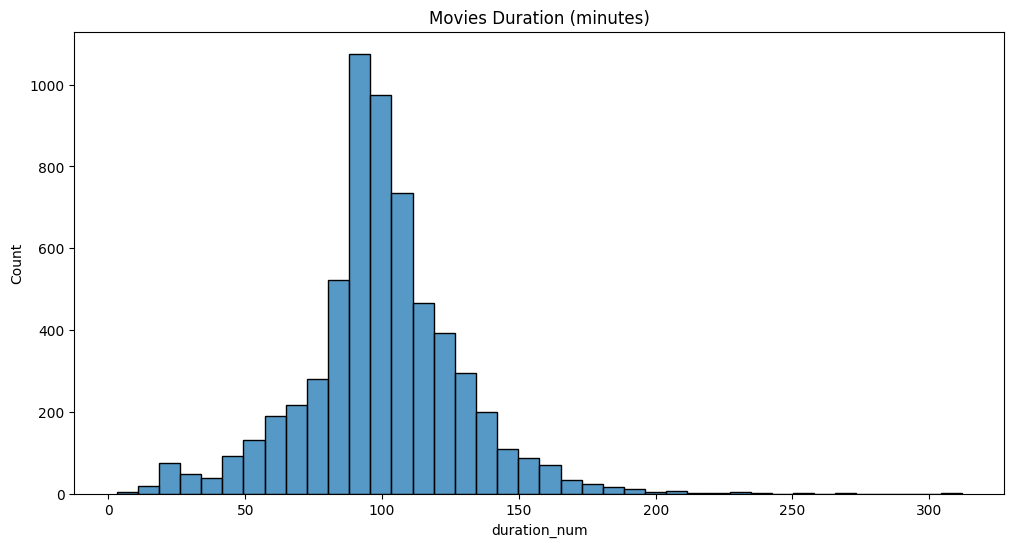

In [51]:
plt.figure(figsize=(12, 6))
plt.title('Movies Duration (minutes)')
sns.histplot(data= movies , x= 'duration_num' , bins= 40)
plt.show()

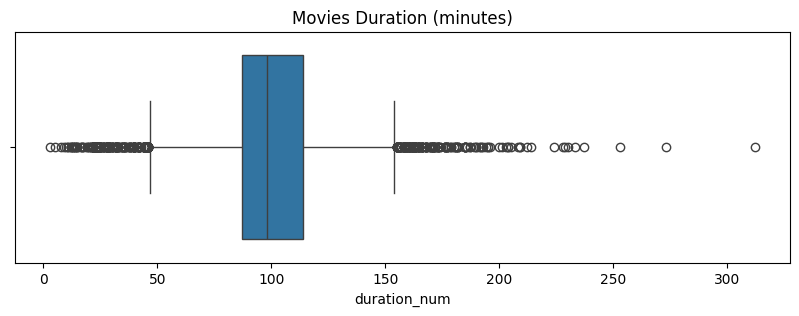

In [52]:
plt.figure(figsize= (10,3))
plt.title('Movies Duration (minutes)')
sns.boxplot(x= movies['duration_num'])
plt.show()

In [53]:
tv_shows['duration_num'].value_counts().sort_index()

duration_num
1     1790
2      421
3      198
4       94
5       64
6       33
7       23
8       17
9        9
10       6
11       1
12       2
13       2
15       2
17       1
Name: count, dtype: int64

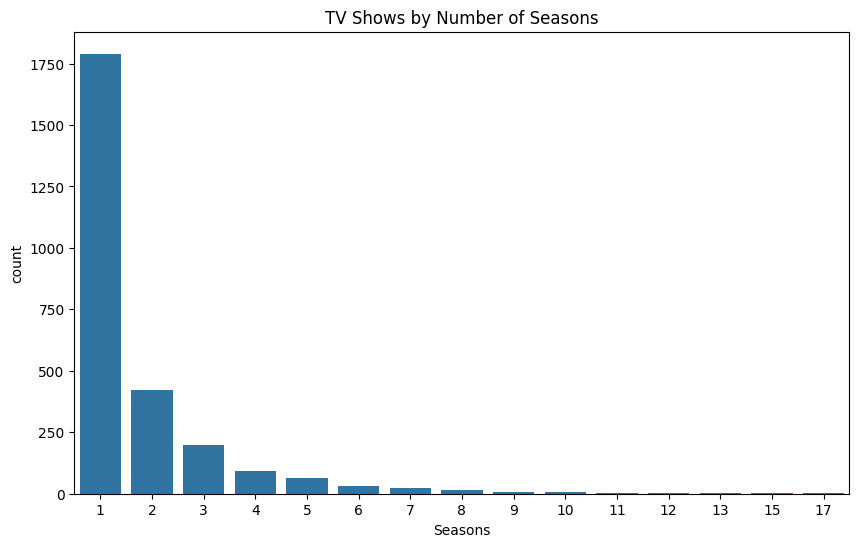

In [54]:
plt.figure(figsize= (10,6))
plt.title('TV Shows by Number of Seasons')
sns.countplot(data= tv_shows , x= 'duration_num')
plt.xlabel('Seasons')
plt.show()